# 03_tune — ②의 하이퍼파라미터 튜닝 (초안: core 담당 2026-11-26, 실행·검증: xgb 담당)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Walnutbrown/kdt14th-lendingclub/blob/main/notebooks/03_tune.ipynb)

설정은 모두 `00_config`의 `TUNE`(2026-11-26 확정, 근거 문헌 없음 → 방법 절에 그대로 기재)에서 읽습니다.

- Dev 전체, 층화 3-겹 CV, 겹마다 전처리를 학습 겹에서만 다시 학습
- Optuna TPE 30회(seed 42), 목표는 검증 겹 logloss 평균
- 트리 수는 검증 겹 조기 종료로 정하고, 최종 트리 수 = 가장 좋은 시도의 겹별 최적 반복 수 평균
- ③은 같은 값을 씁니다(`MONO_HP_MODE = "same_as_xgb"`)

**결과 반영:** 이 노트북은 `contract/xgb_params.json`과 부록 B 표·그림을 만듭니다. `00_config`의 `XGB_PARAMS`는 core 담당이 이 값으로 바꾸고 `pending()`을 풉니다. 그 뒤에 ②③ B=100을 돌립니다.

`DRY_RUN = True`면 Dev 5만 건, 3회 시도로 코드만 시험합니다(결과 파일 이름 앞에 `_dryrun_`).

In [2]:
SKIP_LIB_TESTS = True
%run -i ./00_config.ipynb
%run -i ./lib_prep.ipynb
import time, optuna
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

DRY_RUN = False
N_TRIALS = 3 if DRY_RUN else TUNE["n_trials"]
PREFIX = "_dryrun_" if DRY_RUN else ""
from matplotlib import font_manager
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ("AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR") if f in _have), "DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False
(REPORT_DIR / "tables").mkdir(parents=True, exist_ok=True); (REPORT_DIR / "figures").mkdir(parents=True, exist_ok=True)

X = pd.read_parquet(DATA_DIR / "dev_X_raw.parquet")
y = pd.read_parquet(DATA_DIR / "dev_meta.parquet")["y"].to_numpy()
if DRY_RUN:
    keep = np.random.default_rng(SEED).choice(len(X), 50_000, replace=False)
    X, y = X.iloc[keep].reset_index(drop=True), y[keep]
CATS = load_categories()
print(X.shape, f"부도율 {y.mean():.4f} | 시도 {N_TRIALS}회")

[config 2026-11-26] 해시 a01f81ea67d1 | STAGE=dev | 미결 3개 (B_TEST, DELTA, XGB_PARAMS), 임시값으로 실행 중
[lib_prep] 해시 e07ddd6943c5


/opt/anaconda3/envs/fintech/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(666195, 37) 부도율 0.1626 | 시도 30회


In [3]:
# 1. 겹 나누기와 겹별 전처리 (전처리는 하이퍼파라미터와 무관하므로 한 번만)
skf = StratifiedKFold(TUNE["cv_folds"], shuffle=True, random_state=SEED)
FOLDS = []
for tr, va in skf.split(X, y):
    prep = make_preprocessor("xgb", CATS).fit(X.iloc[tr])
    check_columns(prep, "xgb")
    FOLDS.append((prep.transform(X.iloc[tr]), y[tr], prep.transform(X.iloc[va]), y[va]))
print(f"{len(FOLDS)}겹 준비")

3겹 준비


In [4]:
# 2. 탐색 공간 (TUNE['space']: (하한, 상한) 또는 (하한, 상한, 'log'); max_depth는 정수)
def suggest(trial):
    out = {}
    for name, spec in TUNE["space"].items():
        lo, hi, *opt = spec
        if name == "max_depth":
            out[name] = trial.suggest_int(name, lo, hi)
        else:
            out[name] = trial.suggest_float(name, lo, hi, log=("log" in opt))
    return out

def objective(trial):
    params = suggest(trial); losses, iters = [], []
    for Xtr, ytr, Xva, yva in FOLDS:
        m = XGBClassifier(**{**XGB_FIXED, **params, "n_estimators": TUNE["max_trees"],
                             "early_stopping_rounds": TUNE["early_stopping_rounds"]})
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)   # 조기 종료는 튜닝 CV 안에서만 (부트스트랩 OOB에서는 금지)
        losses.append(m.best_score); iters.append(m.best_iteration + 1)
    trial.set_user_attr("fold_logloss", losses); trial.set_user_attr("fold_trees", iters)
    return float(np.mean(losses))

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=TUNE["sampler_seed"]))
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS, callbacks=[lambda s, t: print(f"시도 {t.number:2d} logloss {t.value:.5f} | 최고 {s.best_value:.5f} | {time.time() - t0:.0f}초")])

시도  0 logloss 0.40900 | 최고 0.40900 | 14초
시도  1 logloss 0.40895 | 최고 0.40895 | 48초
시도  2 logloss 0.40846 | 최고 0.40846 | 80초
시도  3 logloss 0.40845 | 최고 0.40845 | 124초
시도  4 logloss 0.40911 | 최고 0.40845 | 139초
시도  5 logloss 0.40852 | 최고 0.40845 | 187초
시도  6 logloss 0.40897 | 최고 0.40845 | 242초
시도  7 logloss 0.40902 | 최고 0.40845 | 276초
시도  8 logloss 0.40822 | 최고 0.40822 | 338초
시도  9 logloss 0.40964 | 최고 0.40822 | 350초
시도 10 logloss 0.40932 | 최고 0.40822 | 408초
시도 11 logloss 0.40825 | 최고 0.40822 | 473초
시도 12 logloss 0.40837 | 최고 0.40822 | 531초
시도 13 logloss 0.40820 | 최고 0.40820 | 592초
시도 14 logloss 0.40823 | 최고 0.40820 | 663초
시도 15 logloss 0.40825 | 최고 0.40820 | 717초
시도 16 logloss 0.40846 | 최고 0.40820 | 782초
시도 17 logloss 0.40841 | 최고 0.40820 | 823초
시도 18 logloss 0.40833 | 최고 0.40820 | 884초
시도 19 logloss 0.40837 | 최고 0.40820 | 934초
시도 20 logloss 0.40840 | 최고 0.40820 | 977초
시도 21 logloss 0.40822 | 최고 0.40820 | 1048초
시도 22 logloss 0.40821 | 최고 0.40820 | 1104초
시도 23 logloss 0.40812 | 최고 0.40812 

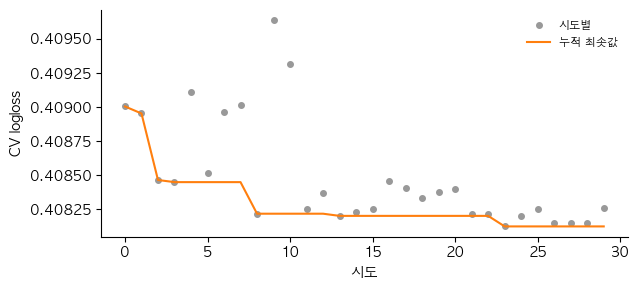

00_config의 XGB_PARAMS를 아래로 바꾸고 pending()을 풀어 주세요(core 담당):
XGB_PARAMS = {'n_estimators': 1871, 'max_depth': 5, 'learning_rate': 0.021939, 'min_child_weight': 96.530704, 'subsample': 0.650524, 'colsample_bytree': 0.956642, 'reg_lambda': 4.787334}


In [5]:
# 3. 결과 저장: contract/xgb_params.json, 부록 B 표(tA1)와 그림(figA1)
best = study.best_trial
n_trees = int(round(np.mean(best.user_attrs["fold_trees"])))   # TUNE['final_trees'] = mean_best_iteration
XGB_PARAMS_NEW = dict(n_estimators=n_trees, **best.params)
trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "duration"))
trials.to_csv(REPORT_DIR / "tables" / f"{PREFIX}tA1_tuning_trials.csv", index=False, encoding="utf-8-sig")
top5 = trials.sort_values("value").head(5)   # [미정·권고] T-7: 상위 5개 파라미터로 OOB a*·ΔSR 재계산 (시간 되면)
rec = dict(xgb_params=XGB_PARAMS_NEW, best_logloss=best.value, fold_logloss=best.user_attrs["fold_logloss"],
           fold_trees=best.user_attrs["fold_trees"], n_trials=N_TRIALS, dry_run=DRY_RUN, n_rows=len(X),
           seconds=round(time.time() - t0), config_hash=config_fingerprint(), lib_prep_hash=LIB_PREP_HASH,
           top5=top5.to_dict("records"), meta=run_meta())
(CONTRACT_DIR / f"{PREFIX}xgb_params.json").write_text(json.dumps(rec, ensure_ascii=False, indent=1, default=str))

fig, ax = plt.subplots(figsize=(6.5, 3))
v = trials["value"].to_numpy()
ax.plot(trials["number"], v, "o", ms=4, color="0.6", label="시도별")
ax.plot(trials["number"], np.minimum.accumulate(v), color="C1", label="누적 최솟값")
ax.set_xlabel("시도"); ax.set_ylabel("CV logloss"); ax.legend(frameon=False, fontsize=8)
for s in ("top", "right"): ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(REPORT_DIR / "figures" / f"{PREFIX}figA1_tuning_history.png", dpi=300); plt.show()

print("00_config의 XGB_PARAMS를 아래로 바꾸고 pending()을 풀어 주세요(core 담당):")
print("XGB_PARAMS = " + repr({k: (round(v, 6) if isinstance(v, float) else v) for k, v in XGB_PARAMS_NEW.items()}))